# Robot manipulador planar de 2 gdl: modelo Euler-Lagrange y simulación

**PIA – Modelado de Sistemas Mecatrónicos (AF 7: Proyecto final)**

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ferxxo-MV/2132259_PIA_MySSM/blob/main/robot_2gdl_euler_lagrange.ipynb)

Este notebook desarrolla el **ejemplo 5.3** de Reyes Cortés, *Robótica: control de robots manipuladores*:

1. Diagrama del robot, variables y los dos sistemas de referencia (tabla 5.1).
2. Ecuaciones de movimiento con el formalismo de **Euler-Lagrange**, derivadas simbólicamente con SymPy, incluyendo los pares de los motores y la fricción.
3. Separación del modelo en $M(q)$, $C(q,\dot q)$, $g(q)$ y $f(\dot q)$, con verificación de sus propiedades.
4. Simulación numérica de **10 s** y visualización de las posiciones articulares $q_1(t)$, $q_2(t)$.

Todo el notebook corre en Google Colab sin instalar nada (NumPy, SciPy, SymPy y Matplotlib vienen incluidos).

In [1]:
import os
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, cumulative_trapezoid
from sympy.physics.vector import dynamicsymbols, vlatex
from IPython.display import display, Math, Image

os.makedirs("figuras", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})

def mostrar(lhs, expr):
    # Muestra 'lhs = expr' en LaTeX (las derivadas temporales se imprimen como puntos)
    display(Math(lhs + " = " + vlatex(expr)))

print("NumPy", np.__version__, "| SymPy", sp.__version__)

NumPy 2.5.3 | SymPy 1.14.0


## 1. Robot manipulador y sistemas de referencia

El robot se mueve en el **plano vertical** $x_0y_0$, por lo que la gravedad actúa sobre ambos eslabones. Se usan dos sistemas de referencia:

* **$\Sigma_0(x_0, y_0, z_0)$, fijo (inercial):** origen en la intersección del eje de giro del hombro con el plano $x_0y_0$; $y_0$ apunta hacia arriba y $z_0$ sale de la hoja (eje de giro).
* **$\Sigma_1(x_1, y_1, z_1)$, móvil:** origen en el codo; $x_1$ está alineado con el eslabón 1 y gira con él.

La posición articular $q_1$ se mide desde la vertical hacia abajo ($-y_0$) en sentido antihorario; $q_2$ es el ángulo del eslabón 2 **relativo** al eslabón 1 (medido desde $x_1$). Con $q_1=q_2=0$ el brazo cuelga verticalmente.

**Tabla 5.1 – Parámetros del robot de 2 gdl**

| Eslabón | Significado | Notación |
|---|---|---|
| 1 (hombro) | Masa del eslabón 1 | $m_1$ |
| | Longitud del eslabón 1 | $l_1$ |
| | Inercia del eslabón 1 | $I_1$ |
| | Centro de masa del eslabón 1 | $l_{c1}$ |
| | Posición articular del eslabón 1 | $q_1$ |
| 2 (codo) | Masa del eslabón 2 | $m_2$ |
| | Longitud del eslabón 2 | $l_2$ |
| | Inercia del eslabón 2 | $I_2$ |
| | Centro de masa del eslabón 2 | $l_{c2}$ |
| | Posición articular del eslabón 2 | $q_2$ |
| | Aceleración debida a la gravedad | $g$ |

Además: $\tau_1,\tau_2$ son los pares de los motores; $b_i$, $f_{ci}$ y $\bar f_i$ los coeficientes de fricción viscosa, de Coulomb y estática de cada articulación.

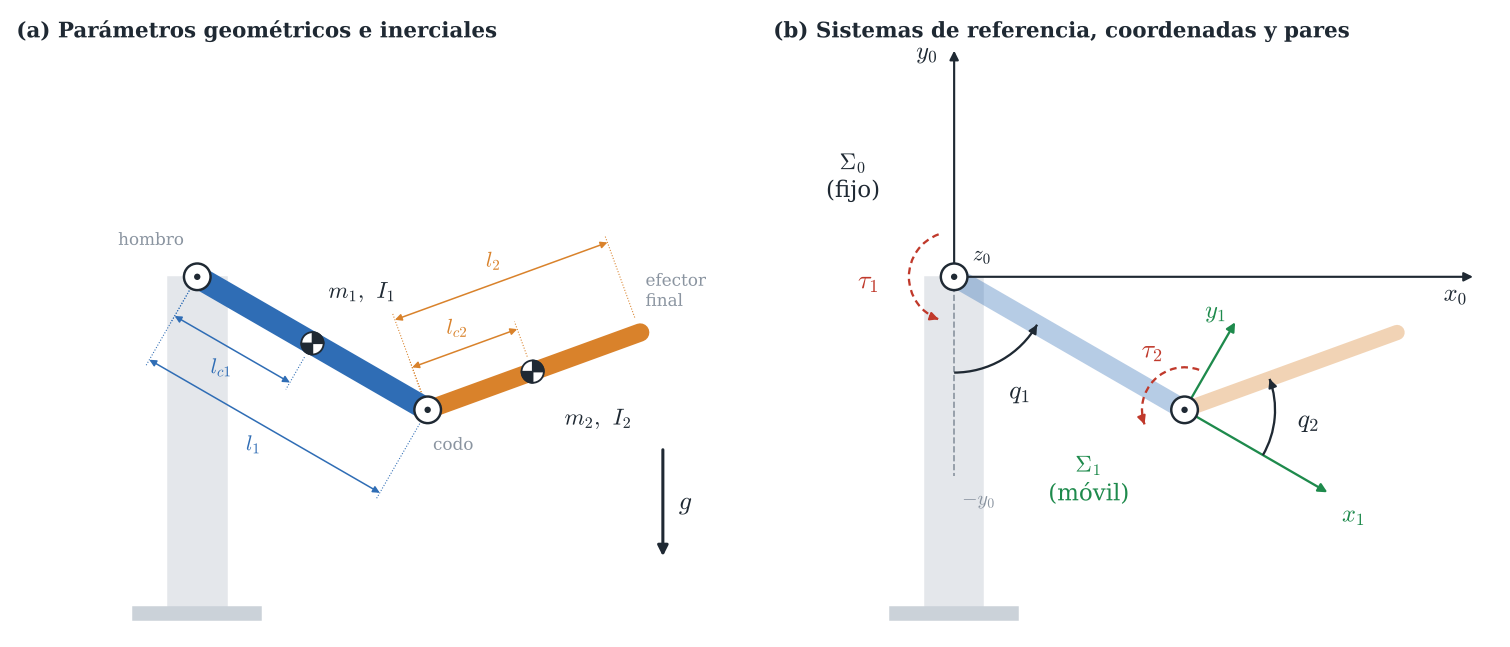

In [2]:
# @title Diagrama del robot (código de la figura) { display-mode: "form" }
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, FancyArrowPatch, Circle, Rectangle, Wedge

plt.rcParams.update({"font.family": "DejaVu Serif", "mathtext.fontset": "cm"})

INK, GRAY = "#1f2933", "#8a94a0"
LINK1, LINK2 = "#2f6db5", "#d9822b"
FRAME1, TAU = "#1e8a4c", "#c0392b"

q1, q2 = np.deg2rad(60), np.deg2rad(50)
l1, l2, lc1, lc2 = 1.0, 0.85, 0.5, 0.42


def u(a):
    """Vector unitario de un eslabón cuyo ángulo se mide desde -y0 (antihorario)."""
    return np.array([np.sin(a), -np.cos(a)])


O = np.zeros(2)
E = l1 * u(q1)
P = E + l2 * u(q1 + q2)
C1, C2 = lc1 * u(q1), E + lc2 * u(q1 + q2)


def arrow(ax, p0, p1, color, lw=1.5, style="-|>", ms=12, z=5):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle=style, mutation_scale=ms, color=color, lw=lw, zorder=z,
                                 shrinkA=0, shrinkB=0))


def draw_arm(ax, alpha=1.0, w1=15, w2=12):
    # pedestal (columna) detrás del hombro
    ax.add_patch(Rectangle((-0.11, -1.25), 0.22, 1.25, color="#e4e7eb", zorder=1))
    ax.add_patch(Rectangle((-0.24, -1.29), 0.48, 0.05, color="#cbd2d9", zorder=1))
    for a, b, c, w in [(O, E, LINK1, w1), (E, P, LINK2, w2)]:
        ax.plot([a[0], b[0]], [a[1], b[1]], color=c, lw=w, solid_capstyle="round", zorder=4, alpha=alpha)
    for p in (O, E):
        ax.add_patch(Circle(p, 0.05, fc="white", ec=INK, lw=1.6, zorder=8))
        ax.add_patch(Circle(p, 0.012, fc=INK, zorder=9))


def com(ax, c):
    ax.add_patch(Circle(c, 0.042, fc="white", ec=INK, lw=1.2, zorder=9))
    ax.add_patch(Wedge(c, 0.042, 0, 90, color=INK, zorder=10))
    ax.add_patch(Wedge(c, 0.042, 180, 270, color=INK, zorder=10))


def dim(ax, p0, p1, off, label, color, lab_off=0.08, fs=14):
    d = p1 - p0
    n = np.array([-d[1], d[0]]) / np.linalg.norm(d)
    a, b = p0 + off * n, p1 + off * n
    arrow(ax, a, b, color, lw=1.0, style="<|-|>", ms=9, z=3)
    s = np.sign(off)
    for p, q in ((p0, a), (p1, b)):
        ax.plot([p[0] + 0.06 * s * n[0], q[0] + 0.03 * s * n[0]], [p[1] + 0.06 * s * n[1], q[1] + 0.03 * s * n[1]],
                color=color, lw=0.7, ls=":", zorder=2)
    ax.text(*((a + b) / 2 + lab_off * s * n), label, fontsize=fs, color=color, ha="center", va="center")


def angle_arc(ax, center, r, a_from, a_to, color, label, lab_r, ls="-", lw=1.5, fs=17):
    ax.add_patch(Arc(center, 2 * r, 2 * r, theta1=min(a_from, a_to), theta2=max(a_from, a_to), color=color, lw=lw,
                     zorder=6, linestyle=ls))
    t = np.deg2rad(a_to)
    tip = center + r * np.array([np.cos(t), np.sin(t)])
    tang = np.sign(a_to - a_from) * np.array([-np.sin(t), np.cos(t)])
    arrow(ax, tip - 0.035 * tang, tip, color, lw=1.4, ms=11, z=7)
    am = np.deg2rad((a_from + a_to) / 2)
    ax.text(*(center + lab_r * np.array([np.cos(am), np.sin(am)])), label, fontsize=fs, color=color,
            ha="center", va="center")


math_ang = lambda a: np.rad2deg(a) - 90.0  # ángulo desde -y0 -> ángulo matemático

fig, (axa, axb) = plt.subplots(1, 2, figsize=(14, 6.6), dpi=110)
for ax in (axa, axb):
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_xlim(-0.7, 2.05)
    ax.set_ylim(-1.35, 1.0)

# ---------------- (a) Parámetros geométricos e inerciales ----------------
draw_arm(axa)
com(axa, C1)
com(axa, C2)
dim(axa, O, C1, -0.17, r"$l_{c1}$", LINK1)
dim(axa, O, E, -0.36, r"$l_{1}$", LINK1)
dim(axa, E, C2, 0.17, r"$l_{c2}$", LINK2)
dim(axa, E, P, 0.36, r"$l_{2}$", LINK2)
axa.text(*(C1 + np.array([0.06, 0.17])), r"$m_1,\ I_1$", fontsize=15, color=INK, ha="left")
axa.text(*(C2 + np.array([0.12, -0.2])), r"$m_2,\ I_2$", fontsize=15, color=INK, ha="left")
axa.text(-0.05, 0.12, "hombro", fontsize=11, color=GRAY, ha="right")
axa.text(E[0] + 0.02, E[1] - 0.15, "codo", fontsize=11, color=GRAY, ha="left")
axa.text(P[0] + 0.02, P[1] + 0.1, "efector\nfinal", fontsize=11, color=GRAY, ha="left")
arrow(axa, np.array([1.75, -0.65]), np.array([1.75, -1.05]), INK, lw=2.0, ms=14)
axa.text(1.81, -0.85, r"$g$", fontsize=17, color=INK, va="center")
axa.text(-0.68, 0.9, "(a) Parámetros geométricos e inerciales", fontsize=14, color=INK, weight="bold")

# ---------------- (b) Sistemas de referencia, coordenadas y pares ----------------
draw_arm(axb, alpha=0.35, w1=13, w2=10)
# Σ0 inercial en el hombro
arrow(axb, O, np.array([1.95, 0]), INK, lw=1.4)
arrow(axb, O, np.array([0, 0.85]), INK, lw=1.4)
axb.text(1.93, -0.09, r"$x_0$", fontsize=16, color=INK, ha="right")
axb.text(-0.06, 0.82, r"$y_0$", fontsize=16, color=INK, ha="right")
axb.text(0.07, 0.06, r"$z_0$", fontsize=14, color=INK)
axb.text(-0.38, 0.3, r"$\Sigma_0$" + "\n(fijo)", fontsize=15, color=INK, ha="center")
axb.plot([0, 0], [0, -0.75], ls="--", color=GRAY, lw=1.1, zorder=2)
axb.text(0.03, -0.8, r"$-y_0$", fontsize=13, color=GRAY, va="top")
# Σ1 en el codo, x1 a lo largo del eslabón 1
x1d = u(q1)
y1d = np.array([-x1d[1], x1d[0]])
axb.plot([E[0], E[0] + 0.62 * x1d[0]], [E[1], E[1] + 0.62 * x1d[1]], color=FRAME1, lw=0)  # guía
arrow(axb, E, E + 0.62 * x1d, FRAME1, lw=1.5)
arrow(axb, E, E + 0.38 * y1d, FRAME1, lw=1.5)
axb.text(*(E + 0.66 * x1d + np.array([0.02, -0.02])), r"$x_1$", fontsize=16, color=FRAME1, va="top")
axb.text(*(E + 0.40 * y1d + np.array([-0.04, 0.0])), r"$y_1$", fontsize=16, color=FRAME1, ha="right")
axb.text(E[0] - 0.36, E[1] - 0.34, r"$\Sigma_1$" + "\n(móvil)", fontsize=15, color=FRAME1, ha="center")
# Coordenadas articulares
angle_arc(axb, O, 0.36, -90, math_ang(q1), INK, r"$q_1$", 0.5)
angle_arc(axb, E, 0.34, math_ang(q1), math_ang(q1 + q2), INK, r"$q_2$", 0.47)
# Pares de los motores (más fricción en cada articulación)
angle_arc(axb, O, 0.17, 110, 250, TAU, "", 0.0, ls=(0, (3, 2)))
axb.text(-0.32, -0.02, r"$\tau_1$", fontsize=17, color=TAU, ha="center", va="center")
angle_arc(axb, E, 0.16, 70, 200, TAU, "", 0.0, ls=(0, (3, 2)))
axb.text(E[0] - 0.12, E[1] + 0.22, r"$\tau_2$", fontsize=17, color=TAU, ha="center", va="center")
axb.text(-0.68, 0.9, "(b) Sistemas de referencia, coordenadas y pares", fontsize=14, color=INK, weight="bold")

fig.tight_layout(pad=0.4, w_pad=1.5)
fig.savefig("figuras/diagrama_robot_2gdl.png", dpi=200, bbox_inches="tight", facecolor="white")

plt.show()

## 2. Modelo dinámico por Euler-Lagrange

El lagrangiano es la diferencia entre energía cinética y potencial, $\mathcal{L}(q,\dot q)=\mathcal{K}(q,\dot q)-\mathcal{U}(q)$. Para cada articulación $i=1,2$:

$$
\frac{d}{dt}\left[\frac{\partial \mathcal{L}}{\partial \dot q_i}\right]-\frac{\partial \mathcal{L}}{\partial q_i}=\tau_i - f_i(\dot q_i,\tau_i)
$$

donde $\tau_i$ es el par del motor y $f_i$ la fricción de la articulación. Se sigue el procedimiento del libro paso a paso, pero dejando que SymPy haga el álgebra.

### Paso 1: cinemática directa de los centros de masa

In [3]:
t = sp.symbols("t")
m1, m2, l1, lc1, lc2, I1, I2, g = sp.symbols("m_1 m_2 l_1 l_{c1} l_{c2} I_1 I_2 g", positive=True)
b1, b2, fc1, fc2, fe1, fe2 = sp.symbols(r"b_1 b_2 f_{c1} f_{c2} \bar{f}_1 \bar{f}_2", positive=True)
tau1, tau2 = sp.symbols(r"\tau_1 \tau_2")

q1, q2 = dynamicsymbols("q_1 q_2")
q = sp.Matrix([q1, q2])
qd = q.diff(t)
qdd = qd.diff(t)

# Centros de masa en Σ0 (q medido desde la vertical hacia abajo)
x1 = lc1*sp.sin(q1)
y1 = -lc1*sp.cos(q1)
x2 = l1*sp.sin(q1) + lc2*sp.sin(q1 + q2)
y2 = -l1*sp.cos(q1) - lc2*sp.cos(q1 + q2)

mostrar(r"\begin{bmatrix}x_1\\y_1\end{bmatrix}", sp.Matrix([x1, y1]))
mostrar(r"\begin{bmatrix}x_2\\y_2\end{bmatrix}", sp.Matrix([x2, y2]))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Paso 2: velocidades de los centros de masa (cinemática diferencial)

In [4]:
v1 = sp.Matrix([x1, y1]).diff(t)
v2 = sp.Matrix([x2, y2]).diff(t)
v1v1 = sp.trigsimp(sp.expand((v1.T*v1)[0]))
v2v2 = sp.trigsimp(sp.expand((v2.T*v2)[0]))

mostrar(r"v_1", v1)
mostrar(r"v_2", v2)
mostrar(r"v_1^Tv_1", sp.simplify(v1v1))
mostrar(r"v_2^Tv_2", sp.collect(sp.expand(v2v2), [qd[0]**2, qd[1]**2, qd[0]*qd[1]]))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Paso 3: energías y lagrangiano

$$\mathcal{K}=\tfrac12 m_1 v_1^Tv_1+\tfrac12 I_1\dot q_1^2+\tfrac12 m_2 v_2^Tv_2+\tfrac12 I_2(\dot q_1+\dot q_2)^2$$

La energía potencial se toma con referencia en la posición colgante ($q=0 \Rightarrow \mathcal{U}=0$).

In [5]:
K = sp.Rational(1, 2)*m1*v1v1 + sp.Rational(1, 2)*I1*qd[0]**2 \
    + sp.Rational(1, 2)*m2*v2v2 + sp.Rational(1, 2)*I2*(qd[0] + qd[1])**2
U = m1*g*lc1*(1 - sp.cos(q1)) + m2*g*((l1 + lc2) - (l1*sp.cos(q1) + lc2*sp.cos(q1 + q2)))
L = K - U

mostrar(r"\mathcal{K}(q,\dot q)", sp.collect(sp.expand(K), [qd[0]**2, qd[1]**2, qd[0]*qd[1]]))
mostrar(r"\mathcal{U}(q)", U)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Paso 4: ecuaciones de Euler-Lagrange para cada articulación

In [6]:
dL_dqd = [sp.diff(L, qd[i]) for i in range(2)]
ddt_dL_dqd = [sp.expand(sp.diff(dL_dqd[i], t)) for i in range(2)]
dL_dq = [sp.expand(sp.diff(L, q[i])) for i in range(2)]

for i in range(2):
    n = i + 1
    mostrar(rf"\frac{{\partial \mathcal{{L}}}}{{\partial \dot q_{n}}}", sp.collect(sp.expand(dL_dqd[i]), qd))
    mostrar(rf"\frac{{d}}{{dt}}\left[\frac{{\partial \mathcal{{L}}}}{{\partial \dot q_{n}}}\right]", sp.collect(ddt_dL_dqd[i], qdd))
    mostrar(rf"\frac{{\partial \mathcal{{L}}}}{{\partial q_{n}}}", dL_dq[i])

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Fricción.** Se modela en cada articulación como la combinación lineal de fricción viscosa, de Coulomb y estática (ec. del libro):

$$f_i(\dot q_i,\tau_i)=b_i\dot q_i+f_{ci}\,\mathrm{signo}(\dot q_i)+\big[1-|\mathrm{signo}(\dot q_i)|\big]\,\mathrm{sat}(\tau_i;\bar f_i)$$

El último término sólo actúa con la articulación en reposo ($\dot q_i=0$): la fricción estática equilibra el par aplicado hasta su límite $\bar f_i$.

Despejando el par de cada motor, $\tau_i=\frac{d}{dt}\big[\partial\mathcal{L}/\partial\dot q_i\big]-\partial\mathcal{L}/\partial q_i+f_i$:

In [7]:
sat = sp.Function("sat")
friccion = sp.Matrix([
    b1*qd[0] + fc1*sp.sign(qd[0]) + (1 - sp.Abs(sp.sign(qd[0])))*sat(tau1, fe1),
    b2*qd[1] + fc2*sp.sign(qd[1]) + (1 - sp.Abs(sp.sign(qd[1])))*sat(tau2, fe2),
])

# Parte conservativa (sin fricción) de cada ecuación
tau_L = sp.Matrix([sp.expand(ddt_dL_dqd[i] - dL_dq[i]) for i in range(2)])
tau_total = tau_L + friccion

for i in range(2):
    terminos = sp.collect(tau_L[i], list(qdd), evaluate=False)
    orden = [qdd[0], qdd[1]] + [k for k in terminos if k not in (qdd[0], qdd[1])]
    partes = [vlatex((sp.factor_terms(terminos[k]) if k != 1 else sp.expand(terminos[k])) * k) for k in orden if k in terminos]
    display(Math(rf"\tau_{i+1} = " + " + ".join(partes).replace("+ -", "- ")
                 + r" + \underbrace{" + vlatex(friccion[i]) + r"}_{f_" + str(i+1) + "}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 3. Forma matricial: $M(q)$, $C(q,\dot q)$, $g(q)$ y $f(\dot q,\tau)$

Agrupando términos de aceleración, velocidad y posición, las dos ecuaciones quedan:

$$\tau = M(q)\,\ddot q + C(q,\dot q)\,\dot q + g(q) + f(\dot q,\tau)$$

* $M(q)$: coeficientes de $\ddot q$ (matriz jacobiana de $\tau$ respecto a $\ddot q$).
* $g(q)$: lo que queda con $\dot q=\ddot q=0$; también $g(q)=\partial\mathcal{U}/\partial q$.
* $C(q,\dot q)$: términos centrípetos y de Coriolis. La matriz **no es única** (sólo el vector $C\dot q$ lo es). Se calcula la forma del libro (ec. de la p. 282) y la de **símbolos de Christoffel**, $c_{kj}=\sum_i \tfrac12\big(\tfrac{\partial m_{kj}}{\partial q_i}+\tfrac{\partial m_{ki}}{\partial q_j}-\tfrac{\partial m_{ij}}{\partial q_k}\big)\dot q_i$.

In [8]:
M = sp.simplify(tau_L.jacobian(qdd))
G = sp.simplify(tau_L.subs({qdd[0]: 0, qdd[1]: 0}).subs({qd[0]: 0, qd[1]: 0}))

# C por símbolos de Christoffel
C_chr = sp.zeros(2, 2)
for k in range(2):
    for j in range(2):
        C_chr[k, j] = sp.simplify(sum(sp.Rational(1, 2)*(sp.diff(M[k, j], q[i]) + sp.diff(M[k, i], q[j])
                                                          - sp.diff(M[i, j], q[k]))*qd[i] for i in range(2)))
# C tal como la agrupa el libro
h = m2*l1*lc2*sp.sin(q2)
C_lib = sp.Matrix([[-2*h*qd[1], -h*qd[1]], [h*qd[0], 0]])

mostrar("M(q)", M)
mostrar(r"C(q,\dot q)_{\mathrm{libro}}", C_lib)
mostrar(r"C(q,\dot q)_{\mathrm{Christoffel}}", C_chr)
mostrar("g(q)", G)
mostrar(r"f(\dot q,\tau)", friccion)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Verificaciones

Se comprueba que la separación reproduce exactamente las ecuaciones de Euler-Lagrange y que el modelo cumple las propiedades de la sección 5.3.1 del libro.

In [9]:
cero = lambda e: sp.simplify(e) == sp.zeros(*e.shape)
N_chr = M.diff(t) - 2*C_chr
N_lib = M.diff(t) - 2*C_lib

print("τ_L − (M q̈ + C q̇ + g) = 0  (C del libro):        ", cero(tau_L - (M*qdd + C_lib*qd + G)))
print("C_libro q̇ = C_Christoffel q̇ (vector único):       ", cero(C_lib*qd - C_chr*qd))
print("M(q) es simétrica:                                 ", cero(M - M.T))
print("K = ½ q̇ᵀ M(q) q̇:                                   ", sp.simplify(sp.Rational(1, 2)*(qd.T*M*qd)[0] - K) == 0)
print("g(q) = ∂U/∂q:                                      ", cero(sp.Matrix([U]).jacobian(q).T - G))
print("Ṁ − 2C antisimétrica (Christoffel):                ", cero(N_chr + N_chr.T))
print("Ṁ − 2C antisimétrica (C del libro):                ", cero(N_lib + N_lib.T))
print("q̇ᵀ(Ṁ − 2C)q̇ = 0 con cualquiera de las dos:        ", cero(qd.T*N_lib*qd) and cero(qd.T*N_chr*qd))

τ_L − (M q̈ + C q̇ + g) = 0  (C del libro):         True
C_libro q̇ = C_Christoffel q̇ (vector único):        True
M(q) es simétrica:                                  True
K = ½ q̇ᵀ M(q) q̇:                                    True
g(q) = ∂U/∂q:                                       True
Ṁ − 2C antisimétrica (Christoffel):                 True
Ṁ − 2C antisimétrica (C del libro):                 False
q̇ᵀ(Ṁ − 2C)q̇ = 0 con cualquiera de las dos:         True


Las dos matrices $C$ dan el mismo vector $C\dot q$, así que producen exactamente la misma simulación. Sin embargo, sólo la de Christoffel hace que $\dot M-2C$ sea antisimétrica, propiedad que se usa en el diseño y análisis de controladores (Lyapunov). Con la del libro sólo se cumple la forma cuadrática $\dot q^T(\dot M-2C)\dot q=0$, que es la que garantiza el balance de energía.

## 4. Modelo numérico

Las ecuaciones dependen de los parámetros físicos sólo a través de cinco **parámetros base** (linealidad en los parámetros). El libro da sus valores numéricos para simulación:

| Parámetro base | Expresión | Valor |
|---|---|---|
| $a_1$ | $m_1l_{c1}^2+m_2l_1^2+m_2l_{c2}^2+I_1+I_2$ | 3.117 |
| $a_2$ | $m_2l_1l_{c2}$ | 0.1 |
| $a_3$ | $m_2l_{c2}^2+I_2$ | 0.108 |
| $a_4$ | $g\,(m_1l_{c1}+m_2l_1)$ | 39.3 |
| $a_5$ | $g\,m_2l_{c2}$ | 1.95 |

$$M(q)=\begin{bmatrix}a_1+2a_2\cos q_2 & a_3+a_2\cos q_2\\ a_3+a_2\cos q_2 & a_3\end{bmatrix},\quad C(q,\dot q)=\begin{bmatrix}-2a_2\sin q_2\,\dot q_2 & -a_2\sin q_2\,\dot q_2\\ a_2\sin q_2\,\dot q_1 & 0\end{bmatrix},\quad g(q)=\begin{bmatrix}a_4\sin q_1+a_5\sin(q_1+q_2)\\ a_5\sin(q_1+q_2)\end{bmatrix}$$

$$f(\dot q)=\begin{bmatrix}1.86\,\dot q_1+1.93\,\mathrm{signo}(\dot q_1)\\ 0.16\,\dot q_2+0.3\,\mathrm{signo}(\dot q_2)\end{bmatrix}$$

> **Nota (errata del libro).** En el texto de la p. 283 el elemento $m_{22}$ aparece como 0, pero el modelo simbólico exige $m_{22}=m_{12}(\cos q_2 = 0)=a_3=0.108$, que es el valor del código fuente 5.5. Con $m_{22}=0$ la matriz de inercia tendría determinante negativo (energía cinética negativa), lo cual es físicamente imposible.

Como en el libro, la simulación incluye fricción viscosa y de Coulomb, pero no la estática. Los pares aplicados (ec. 5.44) son perfiles suaves:

$$\tau_1=(1-e^{-0.8t})\,32+56\sin(16t+0.1)+12\sin(20t+0.15),\qquad \tau_2=(1-e^{-1.8t})\,1.2+8\sin(26t+0.08)+2\sin(12t+0.34)$$

Se asumen unidades del SI (kg·m², N·m, rad).

In [10]:
# Parámetros base (libro, ejemplo 5.3) y coeficientes de fricción
a1, a2, a3, a4, a5 = 3.117, 0.1, 0.108, 39.3, 1.95
b = np.array([1.86, 0.16])      # fricción viscosa  [N·m·s/rad]
fc = np.array([1.93, 0.30])     # fricción de Coulomb [N·m]

def M_num(q):
    c2 = np.cos(q[1])
    return np.array([[a1 + 2*a2*c2, a3 + a2*c2],
                     [a3 + a2*c2,   a3]])

def C_num(q, qd):
    s2 = np.sin(q[1])
    return np.array([[-2*a2*s2*qd[1], -a2*s2*qd[1]],
                     [ a2*s2*qd[0],    0.0]])

def g_num(q):
    return np.array([a4*np.sin(q[0]) + a5*np.sin(q[0] + q[1]),
                     a5*np.sin(q[0] + q[1])])

def f_num(qd):
    return b*qd + fc*np.sign(qd)

def tau_num(t):
    return np.array([(1 - np.exp(-0.8*t))*32 + 56*np.sin(16*t + 0.1) + 12*np.sin(20*t + 0.15),
                     (1 - np.exp(-1.8*t))*1.2 + 8*np.sin(26*t + 0.08) + 2*np.sin(12*t + 0.34)])

# M(q) debe ser definida positiva para todo q2
q2_barrido = np.linspace(-np.pi, np.pi, 721)
lam_min = min(np.linalg.eigvalsh(M_num([0, x])).min() for x in q2_barrido)
print(f"Mínimo eigenvalor de M(q) en q2 ∈ [−π, π]: {lam_min:.4f}  (> 0 → definida positiva)")

M_errata = lambda q: np.array([[a1 + 2*a2*np.cos(q[1]), a3 + a2*np.cos(q[1])], [a3 + a2*np.cos(q[1]), 0.0]])
print(f"Con m22 = 0 (errata): det M(0) = {np.linalg.det(M_errata([0, 0])):.4f}  (< 0 → imposible)")

Mínimo eigenvalor de M(q) en q2 ∈ [−π, π]: 0.0946  (> 0 → definida positiva)
Con m22 = 0 (errata): det M(0) = -0.0433  (< 0 → imposible)


## 5. Simulación de 10 s

Con el estado $x=[q_1,\,q_2,\,\dot q_1,\,\dot q_2]^T$, el modelo se escribe en variables de estado despejando la aceleración:

$$\dot x=\begin{bmatrix}\dot q\\ M(q)^{-1}\big[\tau(t)-C(q,\dot q)\dot q-g(q)-f(\dot q)\big]\end{bmatrix},\qquad x(0)=0$$

Se integra con Runge-Kutta 4(5) (`solve_ivp`, equivalente a `ode45` de MATLAB) con los mismos ajustes del código fuente 5.4: tiempo de 0 a 10 s, paso máximo de 0.0025 s y tolerancia relativa de $10^{-3}$. Se resuelve el sistema lineal $M\ddot q=\dots$ en lugar de invertir $M$.

In [11]:
def robot_2gdl(t, x):
    q, qd = x[:2], x[2:]
    qdd = np.linalg.solve(M_num(q), tau_num(t) - C_num(q, qd) @ qd - g_num(q) - f_num(qd))
    return np.concatenate([qd, qdd])

h_paso, tf = 0.0025, 10.0
ts = np.arange(0.0, tf + h_paso/2, h_paso)
sol = solve_ivp(robot_2gdl, (0.0, tf), np.zeros(4), method="RK45", t_eval=ts,
                max_step=h_paso, first_step=h_paso, rtol=1e-3, atol=1e-6)
q_sim, qd_sim = sol.y[:2], sol.y[2:]
q_deg = np.rad2deg(q_sim)

print(sol.message, f"| {len(ts)} muestras, {sol.nfev} evaluaciones del modelo")
for i in range(2):
    print(f"q{i+1}: mín {q_deg[i].min():7.2f}°, máx {q_deg[i].max():7.2f}°, "
          f"media en 5–10 s {q_deg[i][ts >= 5].mean():7.2f}°, final {q_deg[i][-1]:7.2f}°")

The solver successfully reached the end of the integration interval. | 4001 muestras, 27385 evaluaciones del modelo
q1: mín    0.00°, máx   57.04°, media en 5–10 s   51.26°, final   52.72°
q2: mín  -34.90°, máx   45.92°, media en 5–10 s  -13.23°, final  -28.26°


### Posición de las articulaciones

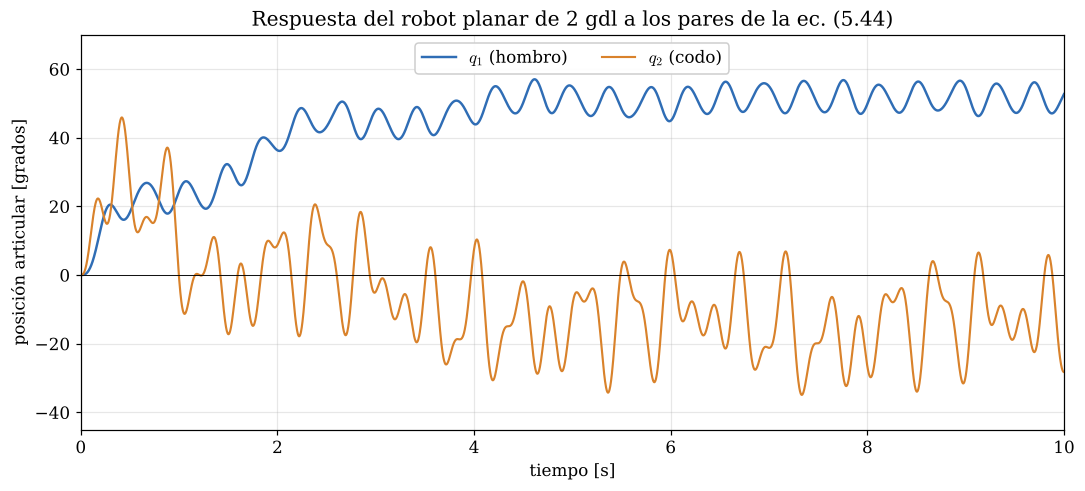

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(ts, q_deg[0], color="#2f6db5", lw=1.6, label=r"$q_1$ (hombro)")
ax.plot(ts, q_deg[1], color="#d9822b", lw=1.4, label=r"$q_2$ (codo)")
ax.axhline(0, color="k", lw=0.6)
ax.set_xlim(0, 10)
ax.set_ylim(-45, 70)
ax.set_xlabel("tiempo [s]")
ax.set_ylabel("posición articular [grados]")
ax.set_title("Respuesta del robot planar de 2 gdl a los pares de la ec. (5.44)")
ax.legend(loc="upper center", ncol=2, framealpha=0.95)
fig.tight_layout()
fig.savefig("figuras/posiciones_articulares.png", dpi=200, facecolor="white")
plt.show()

### Velocidades y pares aplicados

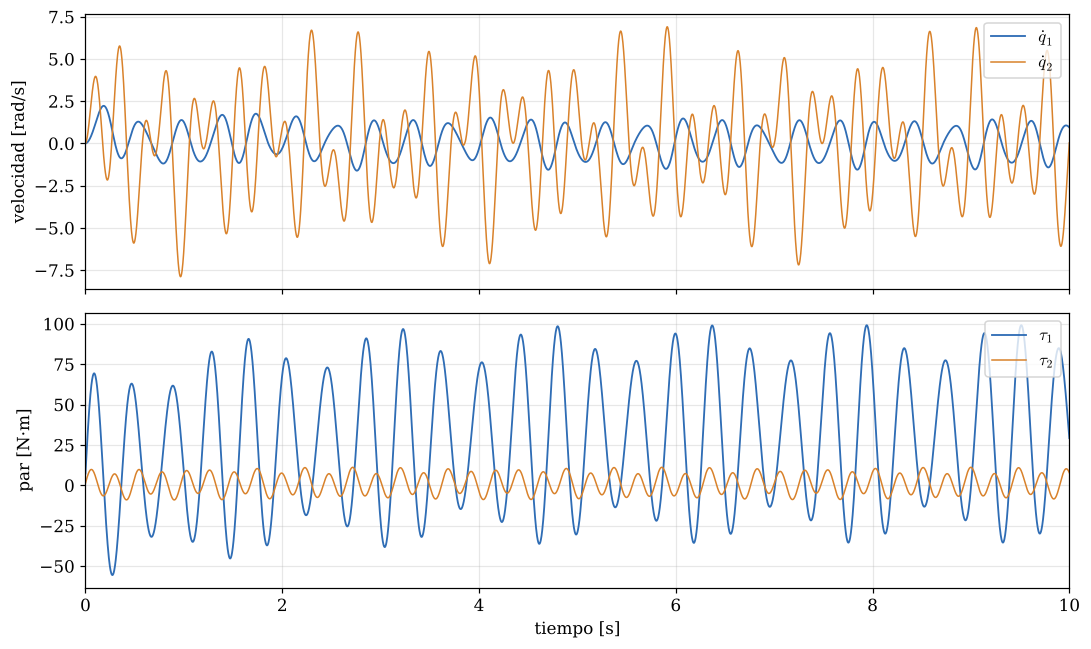

In [13]:
tau_sim = np.array([tau_num(tk) for tk in ts]).T
fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axs[0].plot(ts, qd_sim[0], color="#2f6db5", lw=1.2, label=r"$\dot q_1$")
axs[0].plot(ts, qd_sim[1], color="#d9822b", lw=1.0, label=r"$\dot q_2$")
axs[0].set_ylabel("velocidad [rad/s]")
axs[0].legend(loc="upper right")
axs[1].plot(ts, tau_sim[0], color="#2f6db5", lw=1.2, label=r"$\tau_1$")
axs[1].plot(ts, tau_sim[1], color="#d9822b", lw=1.0, label=r"$\tau_2$")
axs[1].set_ylabel("par [N·m]")
axs[1].set_xlabel("tiempo [s]")
axs[1].legend(loc="upper right")
axs[1].set_xlim(0, 10)
fig.tight_layout()
fig.savefig("figuras/velocidades_y_pares.png", dpi=200, facecolor="white")
plt.show()

### Validación de la simulación

1. **Otro integrador:** se repite la simulación con Runge-Kutta 4 de paso fijo $h=0.0025$ s y se compara.
2. **Balance de energía:** para este modelo $\frac{d}{dt}(\mathcal{K}+\mathcal{U})=\dot q^T\big[\tau-f(\dot q)\big]$ (modelo de energía, sec. 5.3.7). Si la simulación es correcta, la energía mecánica del robot debe igualar el trabajo neto que entregan los motores descontando la fricción.

Diferencia máxima RK45 vs RK4: 0.149°
Error máximo del balance de energía: 0.0018 J  (energía máxima 19.74 J)


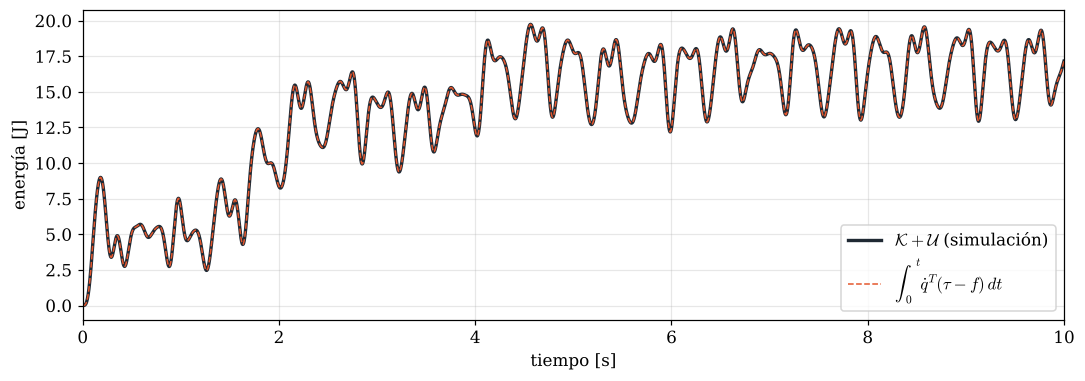

In [14]:
# 1) RK4 de paso fijo
x = np.zeros(4)
X_rk4 = [x]
for k in range(len(ts) - 1):
    tk = ts[k]
    k1 = robot_2gdl(tk, x)
    k2 = robot_2gdl(tk + h_paso/2, x + h_paso/2*k1)
    k3 = robot_2gdl(tk + h_paso/2, x + h_paso/2*k2)
    k4 = robot_2gdl(tk + h_paso, x + h_paso*k3)
    x = x + h_paso/6*(k1 + 2*k2 + 2*k3 + k4)
    X_rk4.append(x)
X_rk4 = np.array(X_rk4).T
print(f"Diferencia máxima RK45 vs RK4: {np.rad2deg(np.abs(X_rk4[:2] - q_sim).max()):.3f}°")

# 2) Balance de energía
Ksim = np.array([0.5*qd_sim[:, k] @ M_num(q_sim[:, k]) @ qd_sim[:, k] for k in range(len(ts))])
Usim = a4*(1 - np.cos(q_sim[0])) + a5*(1 - np.cos(q_sim[0] + q_sim[1]))
Pnet = np.array([qd_sim[:, k] @ (tau_sim[:, k] - f_num(qd_sim[:, k])) for k in range(len(ts))])
W = cumulative_trapezoid(Pnet, ts, initial=0.0)
err = np.abs(Ksim + Usim - W).max()
print(f"Error máximo del balance de energía: {err:.4f} J  (energía máxima {(Ksim + Usim).max():.2f} J)")

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(ts, Ksim + Usim, color="#1f2933", lw=2.2, label=r"$\mathcal{K}+\mathcal{U}$ (simulación)")
ax.plot(ts, W, color="#e4572e", lw=1.0, ls="--", label=r"$\int_0^t \dot q^T(\tau-f)\,dt$")
ax.set_xlabel("tiempo [s]")
ax.set_ylabel("energía [J]")
ax.set_xlim(0, 10)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### Animación del robot

Para dibujar el brazo hacen falta longitudes, que el modelo numérico no da directamente. $l_1$ sí puede deducirse de los parámetros base: $l_1=\dfrac{a_2\,g}{a_5}=\dfrac{(0.1)(9.81)}{1.95}\approx 0.50$ m. Para $l_2$ se supone 0.45 m sólo con fines de visualización (no interviene en la dinámica).

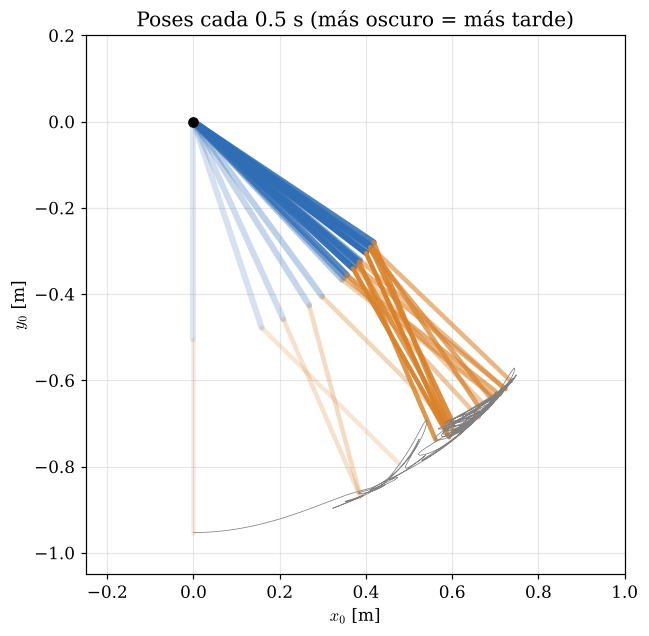

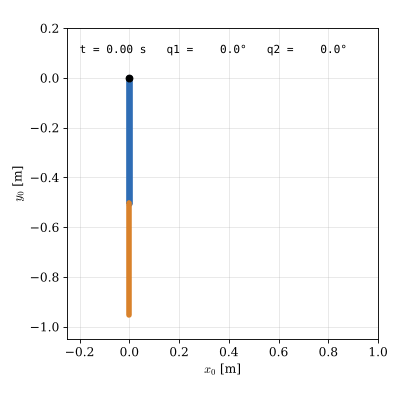

In [15]:
from matplotlib.animation import FuncAnimation, PillowWriter

L1, L2 = a2*9.81/a5, 0.45

def puntos(qk):
    codo = L1*np.array([np.sin(qk[0]), -np.cos(qk[0])])
    efector = codo + L2*np.array([np.sin(qk[0] + qk[1]), -np.cos(qk[0] + qk[1])])
    return codo, efector

# Figura estroboscópica: una pose cada 0.5 s
fig, ax = plt.subplots(figsize=(6, 6))
for k, tk in enumerate(np.arange(0, 10.01, 0.5)):
    i = int(round(tk/h_paso))
    codo, ef = puntos(q_sim[:, i])
    a = 0.15 + 0.85*tk/10
    ax.plot([0, codo[0]], [0, codo[1]], color="#2f6db5", lw=4, alpha=a, solid_capstyle="round")
    ax.plot([codo[0], ef[0]], [codo[1], ef[1]], color="#d9822b", lw=3, alpha=a, solid_capstyle="round")
traza = np.array([puntos(q_sim[:, i])[1] for i in range(len(ts))])
ax.plot(traza[:, 0], traza[:, 1], color="gray", lw=0.5)
ax.plot(0, 0, "ko")
ax.set_aspect("equal"); ax.set_xlim(-0.25, 1.0); ax.set_ylim(-1.05, 0.2)
ax.set_xlabel(r"$x_0$ [m]"); ax.set_ylabel(r"$y_0$ [m]")
ax.set_title("Poses cada 0.5 s (más oscuro = más tarde)")
fig.tight_layout()
fig.savefig("figuras/poses_estroboscopicas.png", dpi=200, facecolor="white")
plt.show()

# Animación en GIF (tiempo real, 25 cuadros/s)
paso = int(0.04/h_paso)
idx = np.arange(0, len(ts), paso)
fig, ax = plt.subplots(figsize=(5, 5), dpi=80)
ax.set_aspect("equal"); ax.set_xlim(-0.25, 1.0); ax.set_ylim(-1.05, 0.2)
ax.set_xlabel(r"$x_0$ [m]"); ax.set_ylabel(r"$y_0$ [m]")
ax.plot(0, 0, "ko", zorder=5)
eslabon1, = ax.plot([], [], color="#2f6db5", lw=6, solid_capstyle="round")
eslabon2, = ax.plot([], [], color="#d9822b", lw=5, solid_capstyle="round")
rastro, = ax.plot([], [], color="gray", lw=0.8)
texto = ax.text(-0.2, 0.1, "", fontsize=10, family="monospace")
fig.tight_layout()

def actualizar(n):
    i = idx[n]
    codo, ef = puntos(q_sim[:, i])
    eslabon1.set_data([0, codo[0]], [0, codo[1]])
    eslabon2.set_data([codo[0], ef[0]], [codo[1], ef[1]])
    rastro.set_data(traza[max(0, i - 400):i + 1, 0], traza[max(0, i - 400):i + 1, 1])
    texto.set_text(f"t = {ts[i]:4.2f} s   q1 = {q_deg[0, i]:6.1f}°   q2 = {q_deg[1, i]:6.1f}°")
    return eslabon1, eslabon2, rastro, texto

anim = FuncAnimation(fig, actualizar, frames=len(idx), blit=True)
anim.save("figuras/robot_2gdl.gif", writer=PillowWriter(fps=25))
plt.close(fig)
display(Image(filename="figuras/robot_2gdl.gif"))

## 6. Observaciones

* **Forma de la respuesta.** El robot arranca del reposo colgando. $q_1$ sube suavemente siguiendo la componente $(1-e^{-0.8t})\,32$ de $\tau_1$ y luego oscila alrededor de un valor medio; $q_2$ oscila con más amplitud y frecuencia porque el eslabón 2 tiene mucha menos inercia ($a_3=0.108$ contra $a_1\approx3.1$).
* **Equilibrio medio.** En promedio, el par medio del hombro (32 N·m) debe equilibrar a la gravedad: $32\approx 39.3\sin q_1+1.95\sin(q_1+q_2)$ (la fricción de Coulomb puede mover ese balance a lo más $\pm1.93$ N·m). Esto acota la media de $q_1$ entre ~47° y ~65°, y la simulación da ≈ 51°.
* **Comparación con la figura 5.6 del libro.** La forma de las curvas es la misma, pero los niveles de la figura (≈ 85° para $q_1$) no son alcanzables con los parámetros numéricos impresos, por el balance anterior. Probablemente la figura se generó con otro juego de parámetros. Nuestra simulación coincide con el modelo publicado y pasa las dos validaciones.
* **Fricción de Coulomb.** La función signo es discontinua en $\dot q_i=0$. Con tolerancias muy estrictas el integrador reduce mucho el paso en cada cambio de signo. Con los ajustes del libro el resultado difiere menos de 0.15° de un RK4 de paso fijo.

## 7. Referencias

1. Reyes Cortés, F. (2020). *Robótica: control de robots manipuladores*. Marcombo. Cap. 5: ejemplo 5.3, tabla 5.1 y códigos fuente 5.3–5.5.
2. Kelly, R., Santibáñez, V. y Loría, A. (2005). *Control of Robot Manipulators in Joint Space*. Springer.
3. Spong, M. W., Hutchinson, S. y Vidyasagar, M. (2020). *Robot Modeling and Control* (2.ª ed.). Wiley.
4. Meurer, A. et al. (2017). SymPy: symbolic computing in Python. *PeerJ Computer Science*, 3, e103.
5. Virtanen, P. et al. (2020). SciPy 1.0: fundamental algorithms for scientific computing in Python. *Nature Methods*, 17, 261–272.